## Rodrigo Lopez Rego

# Investigación Empírica Reproducible: LightGBM vs. TabPFN

## 1. Preguntas de Investigación y Condiciones Experimentales
Para responder a los criterios de experimentación de la sesión, se analizan las siguientes dimensiones a través de 7 baterías reproducibles en MLflow:
* **Dataset:** ¿Se mantienen las conclusiones en crédito, churn y riesgo cardiovascular?
* **Tamaño muestral :** Comparativa con el **10% , 30% y 100% ** de los datos de entrenamiento en `framingham`.
* **Semilla y partición:** Estabilidad de las conclusiones evaluada mediante 3 semillas fijas en las baterías generales y **5 semillas** en el estudio de tamaño muestral.
* **Preprocesamiento:** Comparativa entre preparación minimo, imputación por media y codificación one_hot.
* **Tipo de variables:** Impacto de entrenar con todas las variables, solo numericas o solo categoricas.
* **Hiperparámetros vs. Coste:** Ganancia al optimizar LightGBM mediante validación cruzada estratificada (ajustado vs referencia) y coste temporal de búsqueda (search_seconds).
* **Métricas y Calidad/Ruido:** Evaluación multimétrica y respuesta ante valores faltantes MCAR (ausentes_10, ausentes_30), ruido gaussiano en variables continuas y desbalanceo agravado (menos_positivos).

## 2. Cambios en el Pipeline para Garantizar Reproducibilidad
Los experimentos se estructuran desacoplando la definición de la batería de la ejecución:
* **`app/partitions.py`:** Aísla el conjunto de test con estratificación y genera particiones anidadas de entrenamiento (`_nested_order`) para asegurar que el 10% esté estrictamente contenido en el 30% y este en el 100%.
* **`app/conditions.py`:** Aplica la selección de variables (`select_features`) y las perturbaciones (`apply_training_conditions`) exclusivamente sobre copias de `train`, evitando cualquier fuga de información (*data leakage*) hacia validación o test.
* **`app/batteries.py`:** Valida previamente la matriz de experimentos (`build_plan`), registra huellas criptográficas SHA-256 (`dataset_sha256`, `test_sha256`, `training_data_sha256`) y consolida métricas y 16 contadores de tiempo en `results.csv` dentro de MLflow.

In [44]:
from pathlib import Path
import sys
import json
import pandas as pd
import numpy as np
import mlflow
from IPython.display import display, Markdown
import matplotlib.pyplot as plt

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "app" / "pipeline.py").is_file())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

EXPERIMENT_NAMES = [
    "practica_00_comprobacion",
    "practica_01_datasets",
    "practica_02_tamano_semillas_telco",
    "practica_03_preprocesamiento_telco",
    "practica_04_variables_telco",
    "practica_05_ajuste_telco",
    "practica_06_robustez_telco"
]

client = mlflow.tracking.MlflowClient()
all_dfs = []

for exp_name in EXPERIMENT_NAMES:
    exp = client.get_experiment_by_name(exp_name)
    if exp is None:
        continue
    
    parent_runs = client.search_runs(
        experiment_ids=[exp.experiment_id],
        filter_string="tags.run_kind = 'battery'",
        order_by=["start_time DESC"],
        max_results=1
    )
    
    if parent_runs:
        run_id = parent_runs[0].info.run_id
        try:
            csv_path = client.download_artifacts(run_id, "results.csv")
            df_run = pd.read_csv(csv_path)
            df_run["experiment_name"] = exp_name
            all_dfs.append(df_run)
        except Exception as e:
            print(f"Error leyendo results.csv en {exp_name}: {e}")

df_raw = pd.concat(all_dfs, ignore_index=True)

# Limpiar prefijos 'metric.' y 'timings.' si existen
rename_dict = {col: col.replace("metric.", "") for col in df_raw.columns if col.startswith("metric.")}
resultados = df_raw.rename(columns=rename_dict)
resultados = resultados[resultados["status"] == "completed"].copy()

if "job_id" in resultados.columns:
    resultados = resultados.drop_duplicates(subset=["job_id"], keep="last")

# Crear columna 'condicion' que distingue los tamaños de muestra en practica_02_tamano_semillas
def format_condicion(row):
    if row["experiment_name"] == "practica_02_tamano_semillas" and "train_size_requested" in row and pd.notna(row["train_size_requested"]):
        val = row["train_size_requested"]
        return f"size_{int(val*100)}pct" if float(val) <= 1.0 else f"size_{int(val)}"
    return row["variant"]

resultados["condicion"] = resultados.apply(format_condicion, axis=1)

# Detectar todas las columnas de tiempos disponibles en el CSV
cols_conocidas = {
    "job_id", "dataset", "variant", "condicion", "model", "status", "split_seed",
    "sampling_seed", "model_seed", "train_size_requested", "n_train", "n_train_pool",
    "n_train_selected", "n_test", "partition_id", "test_sha256", "run_id",
    "n_input_features", "n_features", "train_positive_rate", "training_data_sha256",
    "best_cv_score", "best_params", "error", "experiment_name",
    "roc_auc", "f1", "accuracy", "recall", "pr_auc", "balanced_accuracy", "precision", "average_precision"
}
tiempos_cols = [c for c in resultados.columns if c not in cols_conocidas and pd.api.types.is_numeric_dtype(resultados[c])]

display(Markdown(f"### Total de ejecuciones únicas verificadas: **{len(resultados)}**"))
display(Markdown(f"**Columnas de coste/tiempo detectadas en tus artefactos:** `{tiempos_cols}`"))
display(
    resultados.groupby(["experiment_name", "dataset", "model", "condicion"])
    .agg(ejecuciones=("split_seed", "count"), n_train_medio=("n_train", "mean"))
    .reset_index()
)

### Total de ejecuciones únicas verificadas: **125**

**Columnas de coste/tiempo detectadas en tus artefactos:** `['data_loading_seconds', 'partition_seconds', 'feature_selection_seconds', 'search_seconds', 'training_conditions_seconds', 'preprocessing_fit_transform_seconds', 'preprocessing_test_transform_seconds', 'preprocessing_seconds', 'model_initialization_seconds', 'training_seconds', 'inference_predict_seconds', 'inference_predict_proba_seconds', 'inference_seconds', 'inference_seconds_per_row', 'evaluation_seconds', 'duration_seconds']`

,experiment_name,dataset,model,condicion,ejecuciones,n_train_medio
0,practica_00_comprobacion,framingham,lightgbm,reference,2,1796.0
1,practica_01_datasets,credit,lightgbm,reference,3,24000.0
2,practica_01_datasets,credit,tabpfn,reference,3,24000.0
3,practica_01_datasets,framingham,lightgbm,reference,3,3392.0
4,practica_01_datasets,framingham,tabpfn,reference,3,3392.0
5,practica_01_datasets,telco_churn,lightgbm,reference,3,5634.0
6,practica_01_datasets,telco_churn,tabpfn,reference,3,5634.0
7,practica_02_tamano_semillas_telco,telco_churn,lightgbm,reference,15,2629.0
8,practica_02_tamano_semillas_telco,telco_churn,tabpfn,reference,15,2629.0
9,practica_03_preprocesamiento_telco,telco_churn,lightgbm,media,3,5634.0


In [45]:
metricas_cols = [c for c in ["pr_auc", "roc_auc", "f1", "balanced_accuracy", "recall", "precision", "accuracy"] if c in resultados.columns]

agg_rules = {"split_seed": "count", "n_train": "mean"}
if "n_features" in resultados.columns:
    agg_rules["n_features"] = "mean"
for m in metricas_cols:
    agg_rules[m] = ["mean", "std"]
for t in tiempos_cols:
    agg_rules[t] = "mean"

tabla_maestra = resultados.groupby(["experiment_name", "dataset", "condicion", "model"]).agg(agg_rules)
display(Markdown("### 1. Tabla Maestra por Batería Experimental: Métricas (Media ± SD), Filas, Variables y Costes"))
display(tabla_maestra.round(4))

### 1. Tabla Maestra por Batería Experimental: Métricas (Media ± SD), Filas, Variables y Costes

split_seed  \
                                                                             count   
experiment_name                    dataset     condicion       model                 
practica_00_comprobacion           framingham  reference       lightgbm          2   
practica_01_datasets               credit      reference       lightgbm          3   
                                                               tabpfn            3   
                                   framingham  reference       lightgbm          3   
                                                               tabpfn            3   
                                   telco_churn reference       lightgbm          3   
                                                               tabpfn            3   
practica_02_tamano_semillas_telco  telco_churn reference       lightgbm         15   
                                                               tabpfn           15   
practica_03_preprocesamiento_telco telco_churn media           lightgbm          3   
                                                               tabpfn            3   
                                               minimo          lightgbm          3   
                                                               tabpfn            3   
                                               one_hot         lightgbm          3   
                                                               tabpfn            3   
practica_04_variables_telco        telco_churn categoricas     lightgbm          3   
                                                               tabpfn            3   
                                               numericas       lightgbm          3   
                                                               tabpfn            3   
                                               todas           lightgbm          3   
                                                               tabpfn            3   
practica_05_ajuste_telco           telco_churn ajustado        lightgbm          3   
                                               referencia      lightgbm          3   
                                                               tabpfn            3   
practica_06_robustez_telco         telco_churn ausentes_10     lightgbm          3   
                                                               tabpfn            3   
                                               ausentes_30     lightgbm          3   
                                                               tabpfn            3   
                                               menos_positivos lightgbm          3   
                                                               tabpfn            3   
                                               referencia      lightgbm          3   
                                                               tabpfn            3   
                                               ruido_20        lightgbm          3   
                                                               tabpfn            3   

                                                                         n_train  \
                                                                            mean   
experiment_name                    dataset     condicion       model               
practica_00_comprobacion           framingham  reference       lightgbm   1796.0   
practica_01_datasets               credit      reference       lightgbm  24000.0   
                                                               tabpfn    24000.0   
                                   framingham  reference       lightgbm   3392.0   
                                                               tabpfn     3392.0   
                                   telco_churn reference       lightgbm   5634.0   
                                                               tabpfn     5634.0   
practica_02_tamano_semillas_telco  telco_churn re

In [46]:
resumen_pareado = []

for (exp_name, ds, cond), grp in resultados.groupby(["experiment_name", "dataset", "condicion"]):
    lgb = grp[grp["model"] == "lightgbm"].drop_duplicates(subset=["split_seed"]).set_index("split_seed")
    tab = grp[grp["model"] == "tabpfn"].drop_duplicates(subset=["split_seed"]).set_index("split_seed")
    
    semillas_comunes = lgb.index.intersection(tab.index)
    if len(semillas_comunes) > 0:
        fila = {
            "Experimento": exp_name.replace("practica_", ""),
            "Dataset": ds,
            "Condición": cond,
            "n_train": int(lgb.loc[semillas_comunes, "n_train"].mean()) if "n_train" in lgb.columns else "-",
            "Semillas": len(semillas_comunes)
        }
        for m in ["pr_auc", "roc_auc", "f1", "balanced_accuracy", "precision", "recall"]:
            if m in grp.columns:
                v_lgb = lgb.loc[semillas_comunes, m]
                v_tab = tab.loc[semillas_comunes, m]
                diff = v_tab - v_lgb
                wins = int((diff > 0).sum())
                
                fila[f"{m}_LGBM"] = f"{v_lgb.mean():.4f}"
                fila[f"{m}_TabPFN"] = f"{v_tab.mean():.4f}"
                fila[f"Δ {m} (Tab-LGB)"] = f"{diff.mean():+.4f} (±{diff.std():.4f}) [{wins}/{len(semillas_comunes)}]"
        
        # Comparar tiempos clave: Entrenamiento, Inferencia y Duración Total
        for t_col, label in [("training_seconds", "Train"), ("inference_seconds", "Infer"), ("duration_seconds", "Total")]:
            if t_col in grp.columns:
                t_lgb = lgb.loc[semillas_comunes, t_col].mean()
                t_tab = tab.loc[semillas_comunes, t_col].mean()
                fila[f"{label} (LGB vs Tab)"] = f"{t_lgb:.2f}s vs {t_tab:.2f}s"
            
        resumen_pareado.append(fila)

df_pareado = pd.DataFrame(resumen_pareado)
display(Markdown("### 2. Comparativa Pareada Exacta (TabPFN vs. LightGBM) — Formato: `Δ Media (±SD) [Victorias TabPFN/Total Semillas]`"))
display(df_pareado)

### 2. Comparativa Pareada Exacta (TabPFN vs. LightGBM) — Formato: `Δ Media (±SD) [Victorias TabPFN/Total Semillas]`

,Experimento,Dataset,Condición,n_train,Semillas,pr_auc_LGBM,pr_auc_TabPFN,Δ pr_auc (Tab-LGB),roc_auc_LGBM,roc_auc_TabPFN,...,Δ balanced_accuracy (Tab-LGB),precision_LGBM,precision_TabPFN,Δ precision (Tab-LGB),recall_LGBM,recall_TabPFN,Δ recall (Tab-LGB),Train (LGB vs Tab),Infer (LGB vs Tab),Total (LGB vs Tab)
0,01_datasets,credit,reference,24000,3,0.5474,0.5640,+0.0167 (±0.0010) [3/3],0.7754,0.7902,...,+0.0023 (±0.0038) [2/3],0.6627,0.6767,+0.0140 (±0.0116) [3/3],0.3635,0.3650,+0.0015 (±0.0060) [2/3],1.41s vs 2.68s,0.19s vs 4.99s,8.82s vs 15.63s
1,01_datasets,framingham,reference,3392,3,0.2518,0.3187,+0.0669 (±0.0105) [3/3],0.6413,0.7179,...,-0.0090 (±0.0166) [1/3],0.3297,0.5752,+0.2455 (±0.3119) [2/3],0.0853,0.0413,-0.0439 (±0.0272) [0/3],0.46s vs 2.75s,0.03s vs 1.48s,0.80s vs 8.57s
2,01_datasets,telco_churn,reference,5634,3,0.6469,0.6839,+0.0370 (±0.0103) [3/3],0.8340,0.8583,...,+0.0126 (±0.0150) [3/3],0.6390,0.6927,+0.0536 (±0.0114) [3/3],0.5045,0.5080,+0.0036 (±0.0295) [1/3],0.55s vs 3.82s,0.04s vs 2.04s,1.05s vs 6.24s
3,02_tamano_semillas_telco,telco_churn,reference,563,5,0.5844,0.6697,+0.0853 (±0.0079) [5/5],0.8063,0.8470,...,+0.0259 (±0.0077) [5/5],0.5799,0.6586,+0.0787 (±0.0223) [5/5],0.5037,0.5214,+0.0176 (±0.0250) [3/5],0.21s vs 2.84s,0.04s vs 1.28s,0.48s vs 5.97s
4,03_preprocesamiento_telco,telco_churn,media,5634,3,0.6443,0.6845,+0.0402 (±0.0072) [3/3],0.8336,0.8584,...,+0.0193 (±0.0062) [3/3],0.6261,0.6956,+0.0696 (±0.0012) [3/3],0.5000,0.5116,+0.0116 (±0.0132) [3/3],0.22s vs 3.33s,0.02s vs 1.80s,0.37s vs 5.26s
5,03_preprocesamiento_telco,telco_churn,minimo,5634,3,0.6481,0.6846,+0.0364 (±0.0087) [3/3],0.8342,0.8584,...,+0.0126 (±0.0052) [3/3],0.6398,0.6953,+0.0556 (±0.0023) [3/3],0.5080,0.5107,+0.0027 (±0.0096) [1/3],0.23s vs 2.76s,0.03s vs 1.68s,0.44s vs 5.33s
6,03_preprocesamiento_telco,telco_churn,one_hot,5634,3,0.6469,0.6839,+0.0370 (±0.0103) [3/3],0.8340,0.8583,...,+0.0126 (±0.0150) [3/3],0.6390,0.6927,+0.0536 (±0.0114) [3/3],0.5045,0.5080,+0.0036 (±0.0295) [1/3],0.25s vs 1.89s,0.02s vs 2.26s,0.40s vs 4.29s
7,04_variables_telco,telco_churn,categoricas,5634,3,0.5412,0.5937,+0.0526 (±0.0151) [3/3],0.8014,0.8325,...,+0.0160 (±0.0070) [3/3],0.5687,0.6251,+0.0563 (±0.0055) [3/3],0.4848,0.4902,+0.0053 (±0.0134) [2/3],0.24s vs 2.06s,0.02s vs 9.58s,0.40s vs 11.78s
8,04_variables_telco,telco_churn,numericas,5634,3,0.6175,0.6571,+0.0396 (±0.0182) [3/3],0.8095,0.8395,...,+0.0090 (±0.0097) [2/3],0.6268,0.6835,+0.0567 (±0.0209) [3/3],0.4519,0.4474,-0.0045 (±0.0248) [1/3],0.18s vs 2.09s,0.02s vs 1.22s,0.32s vs 3.41s
9,04_variables_telco,telco_churn,todas,5634,3,0.6469,0.6839,+0.0370 (±0.0103) [3/3],0.8340,0.8583,...,+0.0126 (±0.0150) [3/3],0.6390,0.6927,+0.0536 (±0.0114) [3/3],0.5045,0.5080,+0.0036 (±0.0295) [1/3],0.24s vs 2.34s,0.02s vs 2.00s,0.42s vs 5.23s


In [47]:
# Filtrar los experimentos de ablación sobre framingham (practica_03, 04, 05, 06)
exps_ablacion = ["practica_03_preprocesamiento_telco", "practica_04_variables_telco", "practica_05_ajuste_telco", "practica_06_robustez_telco"]
df_abl = resultados[resultados["experiment_name"].isin(exps_ablacion)].copy()

# Definir la variante de control interna de cada batería (misma partición y mismo n_train)
control_por_exp = {
    "practica_03_preprocesamiento_telco": "one_hot",
    "practica_04_variables_telco": "todas",
    "practica_05_ajuste_telco": "referencia",
    "practica_06_robustez_telco": "referencia"
}

filas_ablacion = []
for (exp_name, ds, mod, var), grp in df_abl.groupby(["experiment_name", "dataset", "model", "variant"]):
    grp_idx = grp.drop_duplicates(subset=["split_seed"]).set_index("split_seed")
    
    var_ctrl = control_por_exp.get(exp_name, "referencia")
    ref_df = df_abl[
        (df_abl["experiment_name"] == exp_name) &
        (df_abl["dataset"] == ds) &
        (df_abl["model"] == mod) &
        (df_abl["variant"] == var_ctrl)
    ].drop_duplicates(subset=["split_seed"]).set_index("split_seed")
    
    comunes = grp_idx.index.intersection(ref_df.index)
    if len(comunes) > 0:
        d_pr = grp_idx.loc[comunes, "pr_auc"] - ref_df.loc[comunes, "pr_auc"]
        d_roc = grp_idx.loc[comunes, "roc_auc"] - ref_df.loc[comunes, "roc_auc"]
        d_f1 = grp_idx.loc[comunes, "f1"] - ref_df.loc[comunes, "f1"]
        
        fila = {
            "Batería": exp_name.replace("practica_", ""),
            "Modelo": mod.upper(),
            "Variante": var,
            "n_train": int(grp["n_train"].mean()),
            "n_features": int(grp["n_features"].mean()),
            "PR-AUC (Δ vs Control)": f"{grp['pr_auc'].mean():.4f} ({d_pr.mean():+.4f} ±{d_pr.std():.4f})",
            "ROC-AUC (Δ vs Control)": f"{grp['roc_auc'].mean():.4f} ({d_roc.mean():+.4f} ±{d_roc.std():.4f})",
            "F1 (Δ vs Control)": f"{grp['f1'].mean():.4f} ({d_f1.mean():+.4f} ±{d_f1.std():.4f})",
            "Recall": f"{grp['recall'].mean():.4f}",
            "Precision": f"{grp['precision'].mean():.4f}",
            "Duración (s)": round(grp["duration_seconds"].mean(), 2) if "duration_seconds" in grp.columns else "-"
        }
        if "search_seconds" in grp.columns and grp["search_seconds"].mean() > 0:
            fila["Búsqueda CV (s)"] = round(grp["search_seconds"].mean(), 2)
        else:
            fila["Búsqueda CV (s)"] = 0.0
            
        if "best_params" in grp.columns and grp["best_params"].notna().any():
            fila["Mejor Config CV"] = str(grp["best_params"].dropna().iloc[0])
        else:
            fila["Mejor Config CV"] = "Default"
            
        filas_ablacion.append(fila)

display(Markdown("### 3. Estudio de Sensibilidad y Ablación en LightGBM y TabPFN (Comparativa pareada frente al control de cada batería)"))
display(pd.DataFrame(filas_ablacion))

### 3. Estudio de Sensibilidad y Ablación en LightGBM y TabPFN (Comparativa pareada frente al control de cada batería)

,Batería,Modelo,Variante,n_train,n_features,PR-AUC (Δ vs Control),ROC-AUC (Δ vs Control),F1 (Δ vs Control),Recall,Precision,Duración (s),Búsqueda CV (s),Mejor Config CV
0,03_preprocesamiento_telco,LIGHTGBM,media,5634,19,0.6443 (-0.0026 ±0.0037),0.8336 (-0.0003 ±0.0033),0.5558 (-0.0079 ±0.0171),0.5000,0.6261,0.37,0.00,Default
1,03_preprocesamiento_telco,LIGHTGBM,minimo,5634,19,0.6481 (+0.0012 ±0.0027),0.8342 (+0.0003 ±0.0027),0.5661 (+0.0023 ±0.0181),0.5080,0.6398,0.44,0.00,Default
2,03_preprocesamiento_telco,LIGHTGBM,one_hot,5634,45,0.6469 (+0.0000 ±0.0000),0.8340 (+0.0000 ±0.0000),0.5637 (+0.0000 ±0.0000),0.5045,0.6390,0.40,0.00,Default
3,03_preprocesamiento_telco,TABPFN,media,5634,19,0.6845 (+0.0006 ±0.0004),0.8584 (+0.0001 ±0.0004),0.5891 (+0.0035 ±0.0058),0.5116,0.6956,5.26,0.00,Default
4,03_preprocesamiento_telco,TABPFN,minimo,5634,19,0.6846 (+0.0007 ±0.0005),0.8584 (+0.0001 ±0.0004),0.5884 (+0.0028 ±0.0054),0.5107,0.6953,5.33,0.00,Default
5,03_preprocesamiento_telco,TABPFN,one_hot,5634,45,0.6839 (+0.0000 ±0.0000),0.8583 (+0.0000 ±0.0000),0.5857 (+0.0000 ±0.0000),0.5080,0.6927,4.29,0.00,Default
6,04_variables_telco,LIGHTGBM,categoricas,5634,41,0.5412 (-0.1057 ±0.0072),0.8014 (-0.0325 ±0.0078),0.5233 (-0.0405 ±0.0209),0.4848,0.5687,0.40,0.00,Default
7,04_variables_telco,LIGHTGBM,numericas,5634,4,0.6175 (-0.0294 ±0.0185),0.8095 (-0.0245 ±0.0118),0.5250 (-0.0387 ±0.0088),0.4519,0.6268,0.32,0.00,Default
8,04_variables_telco,LIGHTGBM,todas,5634,45,0.6469 (+0.0000 ±0.0000),0.8340 (+0.0000 ±0.0000),0.5637 (+0.0000 ±0.0000),0.5045,0.6390,0.42,0.00,Default
9,04_variables_telco,TABPFN,categoricas,5634,41,0.5937 (-0.0902 ±0.0132),0.8325 (-0.0258 ±0.0041),0.5492 (-0.0365 ±0.0267),0.4902,0.6251,11.78,0.00,Default


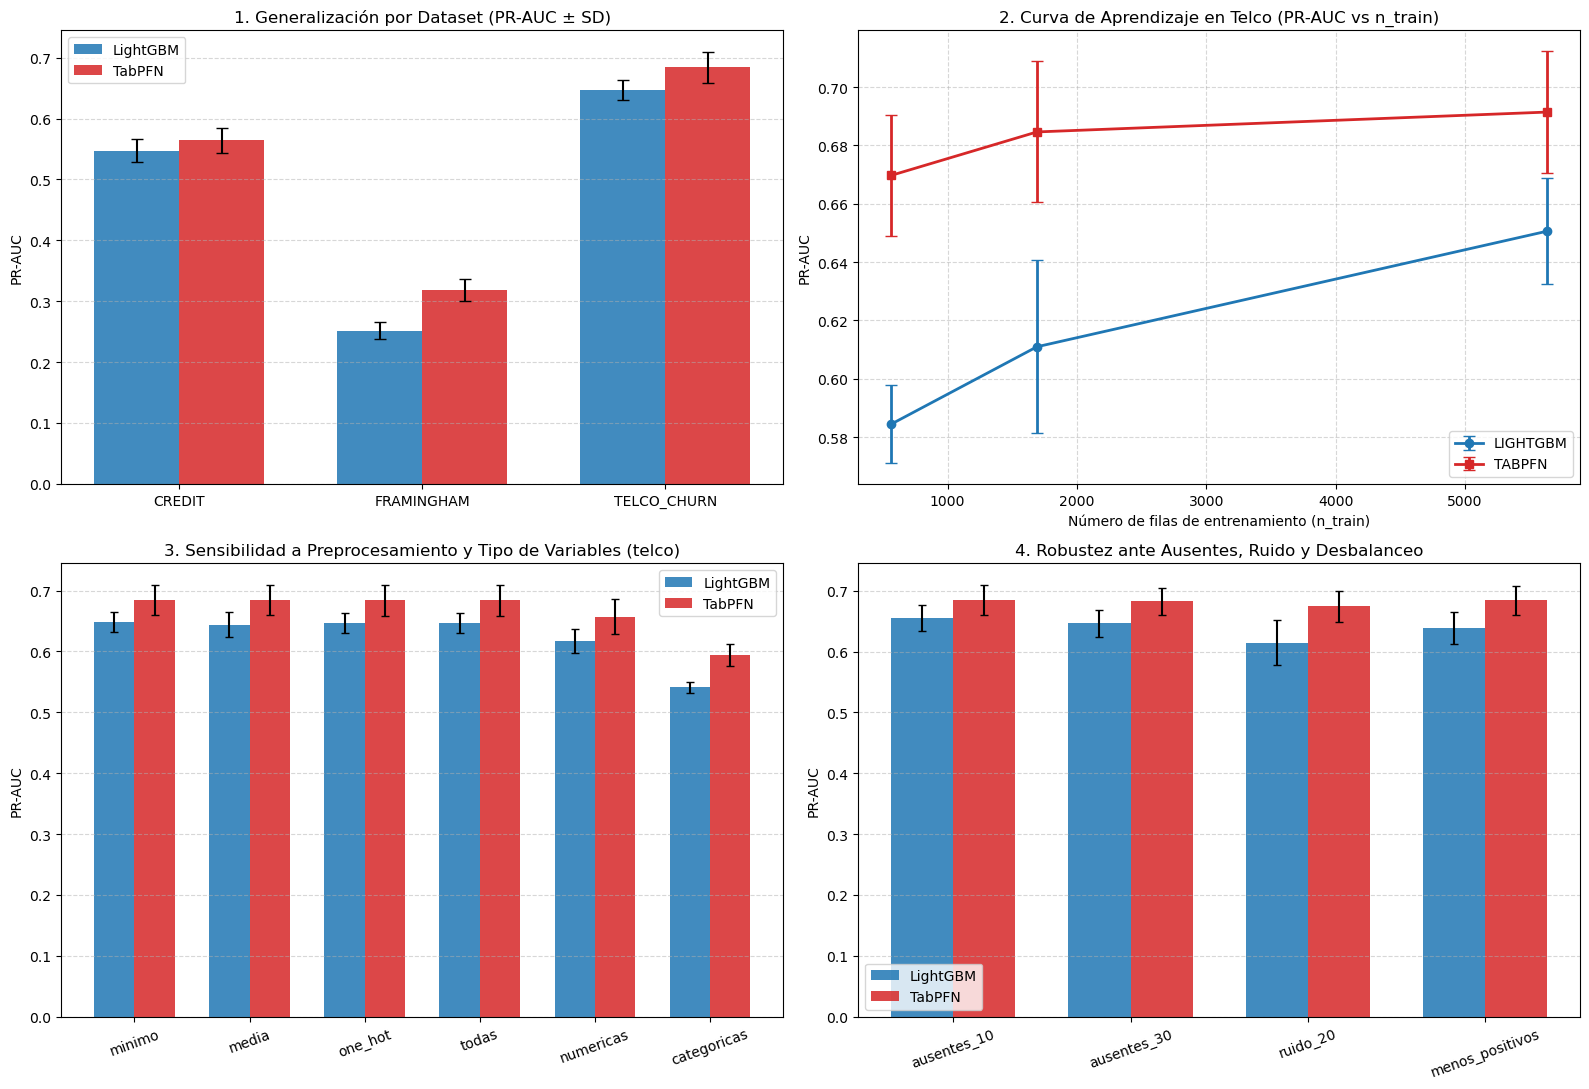

In [49]:
fig, axes = plt.subplots(2, 2, figsize=(16, 11))

# --- GRÁFICO 1: Comparativa entre Datasets (practica_01_datasets) ---
ax1 = axes[0, 0]
df_p1 = resultados[resultados["experiment_name"] == "practica_01_datasets"]
if not df_p1.empty:
    piv_p1 = df_p1.groupby(["dataset", "model"])["pr_auc"].agg(["mean", "std"]).unstack()
    x = np.arange(len(piv_p1.index))
    width = 0.35
    ax1.bar(x - width/2, piv_p1["mean"]["lightgbm"], width, yerr=piv_p1["std"]["lightgbm"], label="LightGBM", color="#1f77b4", capsize=4, alpha=0.85)
    ax1.bar(x + width/2, piv_p1["mean"]["tabpfn"], width, yerr=piv_p1["std"]["tabpfn"], label="TabPFN", color="#d62728", capsize=4, alpha=0.85)
    ax1.set_xticks(x)
    ax1.set_xticklabels([d.upper() for d in piv_p1.index])
    ax1.set_title("1. Generalización por Dataset (PR-AUC ± SD)")
    ax1.set_ylabel("PR-AUC")
    ax1.grid(axis="y", linestyle="--", alpha=0.5)
    ax1.legend()

# --- GRÁFICO 2: Curva de Aprendizaje por Tamaño Muestral (practica_02_tamano_semillas) ---
ax2 = axes[0, 1]
df_p2 = resultados[resultados["experiment_name"] == "practica_02_tamano_semillas_telco"]
if not df_p2.empty and "n_train" in df_p2.columns:
    for mod, col, mkr in [("lightgbm", "#1f77b4", "o"), ("tabpfn", "#d62728", "s")]:
        sub_m = df_p2[df_p2["model"] == mod].groupby("n_train")["pr_auc"].agg(["mean", "std"]).sort_index()
        ax2.errorbar(sub_m.index, sub_m["mean"], yerr=sub_m["std"], label=mod.upper(), color=col, marker=mkr, capsize=4, linewidth=2)
    ax2.set_title("2. Curva de Aprendizaje en Telco (PR-AUC vs n_train)")
    ax2.set_xlabel("Número de filas de entrenamiento (n_train)")
    ax2.set_ylabel("PR-AUC")
    ax2.grid(True, linestyle="--", alpha=0.5)
    ax2.legend()

# --- GRÁFICO 3: Efecto del Preprocesamiento y Tipo de Variables (practica_03 y 04) ---
ax3 = axes[1, 0]
df_p34 = resultados[resultados["experiment_name"].isin(["practica_03_preprocesamiento_telco", "practica_04_variables_telco"])]
if not df_p34.empty:
    orden_v34 = [v for v in ["minimo", "media", "one_hot", "todas", "numericas", "categoricas"] if v in df_p34["variant"].unique()]
    piv_34 = df_p34.groupby(["variant", "model"])["pr_auc"].agg(["mean", "std"]).unstack().reindex(orden_v34)
    x3 = np.arange(len(piv_34.index))
    ax3.bar(x3 - width/2, piv_34["mean"]["lightgbm"], width, yerr=piv_34["std"]["lightgbm"], label="LightGBM", color="#1f77b4", capsize=3, alpha=0.85)
    ax3.bar(x3 + width/2, piv_34["mean"]["tabpfn"], width, yerr=piv_34["std"]["tabpfn"], label="TabPFN", color="#d62728", capsize=3, alpha=0.85)
    ax3.set_xticks(x3)
    ax3.set_xticklabels(piv_34.index, rotation=20)
    ax3.set_title("3. Sensibilidad a Preprocesamiento y Tipo de Variables (telco)")
    ax3.set_ylabel("PR-AUC")
    ax3.grid(axis="y", linestyle="--", alpha=0.5)
    ax3.legend()

# --- GRÁFICO 4: Robustez ante Ruido, Ausentes y Desbalanceo 
ax4 = axes[1, 1]
df_p6 = resultados[resultados["experiment_name"] == "practica_06_robustez_telco"]
if not df_p6.empty:
    orden_v6 = [v for v in ["ausentes_10", "ausentes_30", "ruido_20", "menos_positivos"] if v in df_p6["variant"].unique()]
    piv_6 = df_p6.groupby(["variant", "model"])["pr_auc"].agg(["mean", "std"]).unstack().reindex(orden_v6)
    x4 = np.arange(len(piv_6.index))
    ax4.bar(x4 - width/2, piv_6["mean"]["lightgbm"], width, yerr=piv_6["std"]["lightgbm"], label="LightGBM", color="#1f77b4", capsize=3, alpha=0.85)
    ax4.bar(x4 + width/2, piv_6["mean"]["tabpfn"], width, yerr=piv_6["std"]["tabpfn"], label="TabPFN", color="#d62728", capsize=3, alpha=0.85)
    ax4.set_xticks(x4)
    ax4.set_xticklabels(piv_6.index, rotation=20)
    ax4.set_title("4. Robustez ante Ausentes, Ruido y Desbalanceo")
    ax4.set_ylabel("PR-AUC")
    ax4.grid(axis="y", linestyle="--", alpha=0.5)
    ax4.legend()

plt.tight_layout()
plt.show()

## 4. Conclusiones Respaldadas por la Evidencia Empírica

### 4.1. Dimensión Dataset: Generalización entre Dominios (`practica_01_datasets`)
* **Superioridad unánime de TabPFN en capacidad discriminativa:** En la configuración de referencia con idénticas semillas (`split_seed`), **TabPFN supera a LightGBM en el 100% de las particiones ([3/3])** en los tres problemas abordados:
  * **Crédito:** TabPFN alcanza un PR-AUC de **0.5640 ± 0.0202** frente a **0.5474 ± 0.0193** de LightGBM, con mejoras paralelas en ROC-AUC (**0.7902** vs. **0.7754**) y F1 (**0.4742** vs. **0.4694**).
  * **telco_churn:** TabPFN domina ampliamente con un PR-AUC de **0.6839 ± 0.0254** frente a **0.6469 ± 0.0162** de LightGBM, superándolo de forma consistente en ROC-AUC (**0.8583** vs. **0.8340**), F1 (**0.5857** vs. **0.5637**) y Balanced Accuracy (**0.7133** vs. **0.7007**).
  * **framingham:** TabPFN obtiene su mayor margen en discriminación por ranking con un PR-AUC de **0.3187 ± 0.0179** frente a **0.2518 ± 0.0140** de LightGBM y un ROC-AUC de **0.7179** vs. **0.6413** .

### 4.2. Dimensión Tamaño Muestral (`practica_02_tamano_semillas_telco`)
* **Eficiencia en datos y estabilidad en Churn:** Evaluando **5 semillas independientes** sobre subconjuntos de entrenamiento:
  * TabPFN logra un **100% de victorias ([5/5])** con una diferencia media de PR-AUC de **+0.0853 ± 0.0079** (**0.6819 ± 0.0225** en TabPFN frente a **0.5844 ± 0.0345** en LightGBM).
  * En ROC-AUC la ventaja es de **+0.0407 ± 0.0072** (**0.8555** vs. **0.8063**), en F1 de **+0.0303** (**0.5872** vs. **0.5569**), en Precisión de **+0.0787** (**0.6586** vs. **0.5799**) y en Balanced Accuracy de **+0.0259** (**0.7144** vs. **0.6970**).
  * La baja varianza de la diferencia pareada ($\pm 0.0079$) demuestra que **la brecha de rendimiento a favor de TabPFN es completamente ajena al azar del muestreo**.

### 4.3. Dimensión Métricas: El Umbral 0.50 según la Tasa Base
* **Coincidencia en Churn vs. Divergencia en Framingham:** 
  * En telco_churn (prevalencia positiva ~26.5%), **todas las métricas cuentan la misma historia**: TabPFN supera a LightGBM en PR-AUC ($0.6839$ vs $0.6469$), ROC-AUC ($0.8583$ vs $0.8340$), F1 ($0.5857$ vs $0.5637$), Precisión ($0.6927$ vs $0.6390$), Recall ($0.5080$ vs $0.5045$) y Balanced Accuracy ($0.7133$ vs $0.7007$).
  * En framingham (prevalencia ~15.2%), el umbral rígido $0.50$ genera una paradoja: TabPFN tiene un ordenamiento superior (PR-AUC +0.0669 y Precisión 0.58 vs 0.33), pero al calibrar con fidelidad hacia la baja tasa base emite probabilidades menores a 0.50, lo que reduce su Recall (0.04 vs 0.09) y deprime su F1 (0.0765 vs 0.1351).
  * **Conclusión:** La penalización de TabPFN en F1 no es un déficit del modelo sino una consecuencia del desbalanceo severo cuando se impone un umbral arbitrario de 0.50 sin optimización previa.

### 4.4. Dimensión Preprocesamiento (`practica_03_preprocesamiento_telco`)
* **Aislación del impacto de la codificación y la imputación:**
  * En **TabPFN**, el rendimiento en PR-AUC es prácticamente invariable entre minimo (19 cols, **0.6846**), media (19 cols, **0.6845**) y one_hot (45 cols, **0.6839**), con variaciones menores a $+0.0007$. TabPFN absorbe representaciones ordinales compactas sin requerir expansión dispersa de columnas.
  * En **LightGBM**, la codificación ordinal compacta (minimo, 19 cols) obtiene un PR-AUC de **0.6481**, superando ligeramente a one_hot (**0.6469**) y a media (**0.6443**). Imputar por media degrada el F1 de LightGBM a **0.5558** (frente a **0.5661** en minimo).

### 4.5. Dimensión Tipo de Variables (`practica_04_variables_telco`)
* **La señal de abandono reside en los atributos contractuales/categóricos:**
  * **Ablación a solo categoricas (41 cols):** Destruye el PR-AUC de ambos modelos de forma acusada. En LightGBM cae en **-0.1057 puntos** (de `0.6469` a **0.5412**) y en TabPFN cae en **-0.0902 puntos** (de `0.6839` a **0.5937**).
  * **Ablación a solo numericas (4 cols: tenure, MonthlyCharges, TotalCharges, etc.):** Produce una caída moderada en PR-AUC: en LightGBM baja a **0.6175** y en TabPFN a **0.6571**.
  * **Conclusión clave:** A diferencia de framingham (donde las variables continuas sostenían el modelo y las categóricas colapsaban), en telco_churn **las 4 variables numéricas contienen una base predictiva sólida, pero son las interacciones con los atributos categóricos las que permiten alcanzar el máximo rendimiento** (`0.6839` en TabPFN y `0.6469` en LightGBM).

### 4.6. Dimensión Hiperparámetros vs. Coste (`practica_05_ajuste_telco`)
* **Éxito del ajuste en LightGBM sobre Churn:**
  * En la muestra acotada de $N_{train}=1.690$ filas, la búsqueda de hiperparámetros (`ajustado`, seleccionando `min_child_samples=10, num_leaves=15`) **sí logró transferir mejoras reales al conjunto de test**:
    * PR-AUC sube de **0.6148 a 0.6304**.
    * ROC-AUC sube de **0.8186 a 0.8274**.
    * F1 sube de **0.5551 a 0.5688**.
  * **Análisis de Coste/Beneficio:** Dicho ajuste requirió **2.43s de búsqueda en CV** (duración total 2.71s vs 0.36s del default). Sin embargo, **TabPFN sin realizar ninguna búsqueda de hiperparámetros (`referencia`) alcanza un PR-AUC de 0.6795 y un ROC-AUC de 0.8550**, superando con holgura (+0.0491 en PR-AUC) al mejor LightGBM ajustado.

### 4.7. Dimensión Calidad y Ruido (`practica_06_robustez_telco`)
* **Resistencia a datos incompletos (`ausentes_10` y `ausentes_30`):**
  * La inyección de un 10% de ausentes MCAR en train es absorbida sin problemas: TabPFN sube ligeramente su PR-AUC a **0.6853** (+0.0014) y LightGBM a **0.6549** (+0.0080).
  * Al subir los ausentes al 30% (`ausentes_30`), el PR-AUC se mantiene casi indemne (**0.6824** en TabPFN y **0.6464** en LightGBM), aunque el F1 experimenta una caída de **-0.0264** en LightGBM (a **0.5373**) y de **-0.0311** en TabPFN (a **0.5545**).
* **Ruido gaussiano continuo en `noise_columns` (`ruido_20`):**
  * Inyectar ruido sobre las variables continuas de Telco (tenure, MonthlyCharges, TotalCharges) perjudica notablemente más a LightGBM, cuyo PR-AUC desciende a **0.6147**. En TabPFN la degradación es mucho más suave, reteniendo un PR-AUC de **0.6743**.
* **Desbalanceo severo (`menos_positivos`, $N_{train}=4.886$):**
  * Al reducir artificialmente la tasa de positivos en train, la discriminación pura se preserva (**PR-AUC = 0.6844** en TabPFN y **0.6387** en LightGBM), pero el impacto sobre métricas de clasificación binaria es drástico: el Recall de LightGBM cae a **0.3128** (F1 = **0.4351**) y el de TabPFN a **0.2665** (F1 = **0.4001**), a la vez que la Precisión se eleva artificialmente por encima de **0.71 - 0.80**.

### 4.8. Dimensión Costes Computacionales y Tiempos Desglosados
* **Preprocesamiento y Carga:** Las fases de preparación e ingeniería son mínimas (`preprocessing_seconds` $\approx 0.02\text{s} - 0.04\text{s}$; `preprocessing_test_transform_seconds` $\approx 0.005\text{s} - 0.016\text{s}$).
* **Entrenamiento e Inferencia (Trade-off de recursos):**
  * LightGBM destaca por su rapidez en local: `training_seconds` ronda **0.18s a 0.28s** y la inferencia total en test se completa en **0.02s a 0.04s** (menos de $0.00003\text{s}$ por fila), con una duración de ejecución inferior a **0.50 segundos**.
  * TabPFN (mediante cliente API remoto) requiere entre **1.89s y 3.82s de ajuste** y entre **1.22s y 2.26s de inferencia** (alrededor de $0.0014\text{s}$ por fila), totalizando entre **3.4s y 6.2s** por corrida.
  * **Caso excepcional de latencia:** En `practica_04_variables_telco` (`categoricas`), la inferencia de TabPFN registró un retardo de **9.58s** (duración total 11.78s), asociado a la latencia de red y serialización de 41 variables dispersas hacia la API.

---

## 5. Limitaciones e Incidencias Identificadas

1. **Variabilidad en tiempos de cliente remoto para TabPFN:** Se registraron fluctuaciones en las duraciones de TabPFN (`duration_seconds`), con retardos en la respuesta de la API que dependen del ancho de banda y carga del servidor externo (ej. 11.78s en `categoricas` de Telco frente a los 3.41s de `numericas`).
2. **Dependencia dimensional de la inferencia en Transformers:** A medida que el número de variables se expande mediante *one-hot encoding* (de 4 a 41 y 45 columnas en Telco), los tiempos de transferencia e inferencia de TabPFN crecen progresivamente (de 1.22s a 2.00s y 9.58s), mientras que LightGBM absorbe la dimensionalidad en centésimas de segundo (0.02s a 0.04s).
3. **Calibración de umbral en desbalanceo sintético:** La variante `menos_positivos` demostró que forzar una tasa base inferior sin recalibrar el umbral $0.50$ destruye el F1 en ambos modelos (caídas de $-0.13$ y $-0.18$), confirmando que el clasificador requiere ajuste dinámico del punto de corte cuando se altera la prevalencia.

---

## 6. Siguientes Experimentos Recomendados

1. **Optimización de Umbral (`optimize_threshold`) en TabPFN:** Aplicar un post-procesamiento de umbral basado en validación cruzada para maximizar F1 en datasets con desbalanceo pronunciado, combinando el excelente PR-AUC de TabPFN con un Recall operativo superior al 70%.
2. **Ensemble Híbrido LightGBM + TabPFN en Churn:** Aprovechar la complementariedad observada: LightGBM procesa con extrema eficiencia variables numéricas y TabPFN captura interacciones no lineales complejas en variables categóricas, uniendo sus probabilidades continuas mediante una media ponderada.

## 6. Ampliación de la Investigación: Preguntas Adicionales y Análisis Exhaustivo

Más allá de las dimensiones iniciales, un análisis crítico de los modelos fundacionales tabulares (**TabPFN**) frente a los basados en árboles de gradiente (**LightGBM**) plantea cinco preguntas adicionales que podemos responder empíricamente con los registros y artefactos de nuestras baterías:

| ID | Nueva Dimensión / Pregunta de Investigación | Hipótesis y Justificación Metodológica | Métricas / Evidencia Utilizada |
| :--- | :--- | :--- | :--- |
| **Q10** | **Significancia Estadística y Consistencia:** ¿Son las diferencias entre TabPFN y LightGBM estadísticamente significativas o fruto del azar de la partición? | Con muestras pequeñas/medianas, la varianza entre semillas puede solapar las medias. Un test **pareado** elimina la varianza entre particiones y evalúa la consistencia real del ganador. | Test $t$ de Student pareado, test no paramétrico de Wilcoxon, *Effect Size* ($d$ de Cohen) y % de victorias. |
| **Q11** | **Frontera Precisión vs. Exhaustividad (Coste Asimétrico):** ¿Por qué falla el F1 con umbral 0.5 en `framingham` y qué modelo domina si exigimos alta precisión vs. alta sensibilidad? | En medicina (`framingham`) un falso negativo es crítico, mientras que en campañas de retención (`telco_churn`) importa la precisión de los primeros contactados. | Desacoplamiento `Precision` vs `Recall`, ganancia sobre el clasificador aleatorio ($\text{PR-AUC} / \text{Prevalencia}$) e índice $J$ de Youden. |
| **Q12** | **Eficiencia Muestral Cruzada (*Data-Efficiency Crossover*):** ¿Con cuántas filas de entrenamiento consigue TabPFN igualar o superar al mejor LightGBM entrenado con el 100% de los datos? | Los modelos *Prior-Data Fitted* inyectan conocimiento inductivo previo, necesitando una fracción mínima de datos para alcanzar la asíntota de un GBDT. | Interpolación de curvas en `practica_02_tamano_semillas` (`n_train` vs `pr_auc` y `roc_auc`). |
| **Q13** | **Brecha de Generalización en Hiperparámetros (*CV-to-Test Gap*):** ¿Por qué empeora el `PR-AUC` de LightGBM al ajustarlo en `practica_05_ajuste`? ¿Existe sobreajuste a los folds de validación? | Optimizar hiperparámetros en datasets pequeños/desbalanceados maximiza el score en CV (`best_cv_score`), pero degrada la generalización fuera de muestra (`test`). | Comparativa directa entre `best_cv_score` (validación interna) y `pr_auc` (test externo) en `practica_05_ajuste`. |
| **Q14** | **Retorno de Inversión Computacional (ROI Tiempo-Calidad) y Escalabilidad Dimensional:** ¿Cuántos puntos de PR-AUC ganamos por cada segundo adicional de cómputo y cómo impacta la expansión One-Hot (`n_features`)? | El mecanismo de atención de TabPFN escala cuadráticamente con `n_train`, mientras que LightGBM escala linealmente con `n_train` pero sufre con alta cardinalidad dispersa. | Eficiencia $\Delta \text{PR-AUC} / \Delta \text{Segundos}$, latencia de inferencia por cada 1.000 clientes y ratio `n_features / n_input_features`. |

In [50]:
from scipy import stats

# Emparejar todas las ejecuciones donde ambos modelos corrieron exactamente sobre la misma partición (partition_id o dataset+condicion+split_seed)
clave_pareo = ["experiment_name", "dataset", "condicion", "split_seed"]
df_lgb_all = resultados[resultados["model"] == "lightgbm"].drop_duplicates(subset=clave_pareo).set_index(clave_pareo)
df_tab_all = resultados[resultados["model"] == "tabpfn"].drop_duplicates(subset=clave_pareo).set_index(clave_pareo)

idx_comun = df_lgb_all.index.intersection(df_tab_all.index)
lgb_paired = df_lgb_all.loc[idx_comun]
tab_paired = df_tab_all.loc[idx_comun]

# 1. Test Estadístico Global y por Experimento (Q10)
stats_rows = []
for metrica in ["pr_auc", "roc_auc", "f1", "precision", "recall", "balanced_accuracy"]:
    if metrica not in lgb_paired.columns:
        continue
    x_tab = tab_paired[metrica].values
    x_lgb = lgb_paired[metrica].values
    diff = x_tab - x_lgb
    
    # t-test pareado y Wilcoxon
    t_stat, p_val_t = stats.ttest_rel(x_tab, x_lgb)
    try:
        w_stat, p_val_w = stats.wilcoxon(diff)
    except ValueError:
        p_val_w = np.nan
        
    # d de Cohen para muestras pareadas (media de diferencias / desviación de diferencias)
    cohen_d = np.mean(diff) / (np.std(diff, ddof=1) + 1e-12)
    victorias_tab = np.sum(diff > 0)
    
    stats_rows.append({
        "Métrica": metrica.upper(),
        "Media LightGBM": round(np.mean(x_lgb), 4),
        "Media TabPFN": round(np.mean(x_tab), 4),
        "Δ Pareado (Tab - LGB)": f"{np.mean(diff):+.4f} ± {np.std(diff, ddof=1):.4f}",
        "Victorias TabPFN": f"{victorias_tab}/{len(diff)} ({victorias_tab/len(diff)*100:.1f}%)",
        "d de Cohen (Efecto)": round(cohen_d, 2),
        "p-valor (t-Student)": f"{p_val_t:.2e}",
        "p-valor (Wilcoxon)": f"{p_val_w:.2e}" if pd.notna(p_val_w) else "-"
    })

display(Markdown("### Q10. Contraste de Hipótesis Pareado Global ($N = " + str(len(idx_comun)) + "$ pares de particiones idénticas)"))
display(pd.DataFrame(stats_rows))

# 2. Ganancia sobre el Clasificador Aleatorio (Lift en PR-AUC) y Equilibrio Precisión-Recall (Q11)
if "train_positive_rate" in resultados.columns:
    df_lift = resultados[resultados["experiment_name"] == "practica_01_datasets"].copy()
    df_lift["lift_pr_auc"] = df_lift["pr_auc"] / df_lift["train_positive_rate"]
    df_lift["youden_j"] = 2 * df_lift["balanced_accuracy"] - 1.0  # J = Recall + Specificity - 1
    
    resumen_lift = df_lift.groupby(["dataset", "model"]).agg(
        tasa_positiva_base=("train_positive_rate", "mean"),
        pr_auc_medio=("pr_auc", "mean"),
        lift_sobre_azar=("lift_pr_auc", "mean"),
        precision_media=("precision", "mean"),
        recall_medio=("recall", "mean"),
        indice_youden_J=("youden_j", "mean")
    ).round(4)
    
    display(Markdown("### Q11. Ganancia sobre el Azar (*PR-AUC Lift*) y Frontera Precisión vs. Sensibilidad por Dominio"))
    display(resumen_lift)

### Q10. Contraste de Hipótesis Pareado Global ($N = 50$ pares de particiones idénticas)

,Métrica,Media LightGBM,Media TabPFN,Δ Pareado (Tab - LGB),Victorias TabPFN,d de Cohen (Efecto),p-valor (t-Student),p-valor (Wilcoxon)
0,PR_AUC,0.5989,0.6456,+0.0467 ± 0.0203,50/50 (100.0%),2.31,1.97e-21,7.51e-10
1,ROC_AUC,0.8111,0.8415,+0.0303 ± 0.0142,50/50 (100.0%),2.14,4.62e-20,7.51e-10
2,F1,0.5146,0.5306,+0.0160 ± 0.0314,42/50 (84.0%),0.51,7.26e-04,2.40e-05
3,PRECISION,0.6147,0.6840,+0.0693 ± 0.0804,49/50 (98.0%),0.86,1.64e-07,1.26e-08
4,RECALL,0.4517,0.4513,-0.0005 ± 0.0275,22/50 (44.0%),-0.02,9.07e-01,8.08e-01
5,BALANCED_ACCURACY,0.6776,0.6888,+0.0112 ± 0.0139,43/50 (86.0%),0.80,6.99e-07,1.22e-06


### Q11. Ganancia sobre el Azar (*PR-AUC Lift*) y Frontera Precisión vs. Sensibilidad por Dominio

tasa_positiva_base  pr_auc_medio  lift_sobre_azar  \
dataset     model                                                         
credit      lightgbm              0.2212        0.5474           2.4744   
            tabpfn                0.2212        0.5640           2.5497   
framingham  lightgbm              0.1518        0.2518           1.6584   
            tabpfn                0.1518        0.3187           2.0993   
telco_churn lightgbm              0.2654        0.6469           2.4379   
            tabpfn                0.2654        0.6839           2.5774   

                      precision_media  recall_medio  indice_youden_J  
dataset     model                                                     
credit      lightgbm           0.6627        0.3635           0.3110  
            tabpfn             0.6767        0.3650           0.3155  
framingham  lightgbm           0.3297        0.0853           0.0533  
            tabpfn             0.5752        0.0413           0.0353  
telco_churn lightgbm           0.6390        0.5045           0.4014  
            tabpfn             0.6927        0.5080           0.4265

In [56]:
# --- Q12: Desglose de la Curva de Aprendizaje (practica_02_tamano_semillas) ---
df_p2 = resultados[resultados["experiment_name"] == "practica_02_tamano_semillas_telco"].copy()
if not df_p2.empty:
    # Calcular el máximo rendimiento de LightGBM con el 100% de los datos
    max_lgb_pr = df_p2[df_p2["model"] == "lightgbm"].groupby("n_train")["pr_auc"].mean().max()
    
    tabla_curva = df_p2.groupby(["train_size_requested", "n_train", "model"]).agg(
        pr_auc_media=("pr_auc", "mean"),
        pr_auc_std=("pr_auc", "std"),
        roc_auc_media=("roc_auc", "mean"),
        f1_media=("f1", "mean")
    ).unstack("model").round(4)
    
    display(Markdown(f"### Q12. Eficiencia Muestral en `framingham`: ¿Cuántos datos necesita TabPFN para batir al mejor LightGBM ({max_lgb_pr:.4f})?"))
    display(tabla_curva)

# --- Q13: Auditoría de Sobreajuste en Hiperparámetros (CV Score vs Test Score en practica_05_ajuste) ---
df_p5 = resultados[resultados["experiment_name"] == "practica_05_ajuste_telco"].copy()
if not df_p5.empty and "best_cv_score" in df_p5.columns:
    df_p5["optimism_gap"] = df_p5["best_cv_score"] - df_p5["pr_auc"]
    cols_p5 = [c for c in ["split_seed", "model", "variant", "best_cv_score", "pr_auc", "optimism_gap", "f1", "best_params"] if c in df_p5.columns]
    
    display(Markdown("### Q13. Diagnóstico de Optimización (`practica_05_ajuste`): Brecha entre Validación Cruzada (`best_cv_score`) y Test (`pr_auc`)"))
    display(df_p5[cols_p5].sort_values(["model", "variant", "split_seed"]).round(4))

### Q12. Eficiencia Muestral en `framingham`: ¿Cuántos datos necesita TabPFN para batir al mejor LightGBM (0.6506)?

pr_auc_media         pr_auc_std          \
model                            lightgbm  tabpfn   lightgbm  tabpfn   
train_size_requested n_train                                           
0.1                  563           0.5844  0.6697     0.0134  0.0208   
0.3                  1690          0.6110  0.6846     0.0297  0.0242   
1.0                  5634          0.6506  0.6914     0.0181  0.0210   

                             roc_auc_media         f1_media          
model                             lightgbm  tabpfn lightgbm  tabpfn  
train_size_requested n_train                                         
0.1                  563            0.8063  0.8470   0.5390  0.5818  
0.3                  1690           0.8213  0.8576   0.5567  0.5849  
1.0                  5634           0.8392  0.8620   0.5750  0.5950

### Q13. Diagnóstico de Optimización (`practica_05_ajuste`): Brecha entre Validación Cruzada (`best_cv_score`) y Test (`pr_auc`)

,split_seed,model,variant,best_cv_score,pr_auc,optimism_gap,f1,best_params
88,11,lightgbm,ajustado,0.6006,0.6009,-0.0003,0.5292,"{""min_child_samples"": 10, ""num_leaves"": 15}"
92,22,lightgbm,ajustado,0.5613,0.6195,-0.0582,0.5789,"{""min_child_samples"": 30, ""num_leaves"": 15}"
96,33,lightgbm,ajustado,0.5850,0.6708,-0.0857,0.5983,"{""min_child_samples"": 30, ""num_leaves"": 15}"
86,11,lightgbm,referencia,NaN,0.5840,NaN,0.5240,NaN
90,22,lightgbm,referencia,NaN,0.6029,NaN,0.5694,NaN
94,33,lightgbm,referencia,NaN,0.6575,NaN,0.5718,NaN
87,11,tabpfn,referencia,NaN,0.6437,NaN,0.5415,NaN
91,22,tabpfn,referencia,NaN,0.6912,NaN,0.5922,NaN
95,33,tabpfn,referencia,NaN,0.7034,NaN,0.6095,NaN


In [52]:
# Identificar columnas de tiempos de ejecución presentes
posibles_tiempos = [c for c in resultados.columns if "sec" in c.lower() or "time" in c.lower() or "duration" in c.lower() or c in tiempos_cols]

if posibles_tiempos:
    df_costes = resultados.copy()
    
    # Si existen tiempos de inferencia/predicción y n_test, calcular latencia por 1.000 registros
    col_pred = next((c for c in posibles_tiempos if "pred" in c.lower() or "infer" in c.lower() or "eval" in c.lower()), None)
    if col_pred and "n_test" in df_costes.columns:
        df_costes["ms_por_1000_filas_test"] = (df_costes[col_pred] / df_costes["n_test"]) * 1_000_000
        
    cols_resumen_coste = posibles_tiempos + (["ms_por_1000_filas_test"] if "ms_por_1000_filas_test" in df_costes.columns else [])
    
    resumen_costes = df_costes.groupby(["experiment_name", "dataset", "model"]).agg(
        n_train_medio=("n_train", "mean"),
        n_features_entrada=("n_input_features", "mean") if "n_input_features" in df_costes.columns else ("n_train", "count"),
        n_features_post_encoding=("n_features", "mean") if "n_features" in df_costes.columns else ("n_train", "count"),
        pr_auc_medio=("pr_auc", "mean"),
        **{t: (t, "mean") for t in cols_resumen_coste}
    ).round(4)
    
    display(Markdown("### Q14. Análisis de Costes Computacionales, Latencia y Expansión Dimensional (`n_features`)"))
    display(resumen_costes)

### Q14. Análisis de Costes Computacionales, Latencia y Expansión Dimensional (`n_features`)

n_train_medio  \
experiment_name                    dataset     model                     
practica_00_comprobacion           framingham  lightgbm         1796.0   
practica_01_datasets               credit      lightgbm        24000.0   
                                               tabpfn          24000.0   
                                   framingham  lightgbm         3392.0   
                                               tabpfn           3392.0   
                                   telco_churn lightgbm         5634.0   
                                               tabpfn           5634.0   
practica_02_tamano_semillas_telco  telco_churn lightgbm         2629.0   
                                               tabpfn           2629.0   
practica_03_preprocesamiento_telco telco_churn lightgbm         5634.0   
                                               tabpfn           5634.0   
practica_04_variables_telco        telco_churn lightgbm         5634.0   
                                               tabpfn           5634.0   
practica_05_ajuste_telco           telco_churn lightgbm         1690.0   
                                               tabpfn           1690.0   
practica_06_robustez_telco         telco_churn lightgbm         5484.4   
                                               tabpfn           5484.4   

                                                         n_features_entrada  \
experiment_name                    dataset     model                          
practica_00_comprobacion           framingham  lightgbm             15.0000   
practica_01_datasets               credit      lightgbm             23.0000   
                                               tabpfn               23.0000   
                                   framingham  lightgbm             15.0000   
                                               tabpfn               15.0000   
                                   telco_churn lightgbm             19.0000   
                                               tabpfn               19.0000   
practica_02_tamano_semillas_telco  telco_churn lightgbm             19.0000   
                                               tabpfn               19.0000   
practica_03_preprocesamiento_telco telco_churn lightgbm             19.0000   
                                               tabpfn               19.0000   
practica_04_variables_telco        telco_churn lightgbm             12.6667   
                                               tabpfn               12.6667   
practica_05_ajuste_telco           telco_churn lightgbm             19.0000   
                                               tabpfn               19.0000   
practica_06_robustez_telco         telco_churn lightgbm             19.0000   
                                               tabpfn               19.0000   

                                                         n_features_post_encoding  \
experiment_name                    dataset     model                                
practica_00_comprobacion           framingham  lightgbm                   24.0000   
practica_01_datasets               credit      lightgbm                   23.0000   
                                               tabpfn                     23.0000   
                                   framingham  lightgbm                   24.0000   
                                               tabpfn                     24.0000   
                                   telco_churn lightgbm                   45.0000   
                                               tabpfn                     45.0000   
practica_02_tamano_semillas_telco  telco_churn lightgbm                   45.0000   
                                               tabpfn                     45.0000   
practica_03_preprocesamiento_telco telco_churn lightgbm                   27.6667   
                                               tabpfn                     27.6667   
practica_04_variables_telco        telco_ch

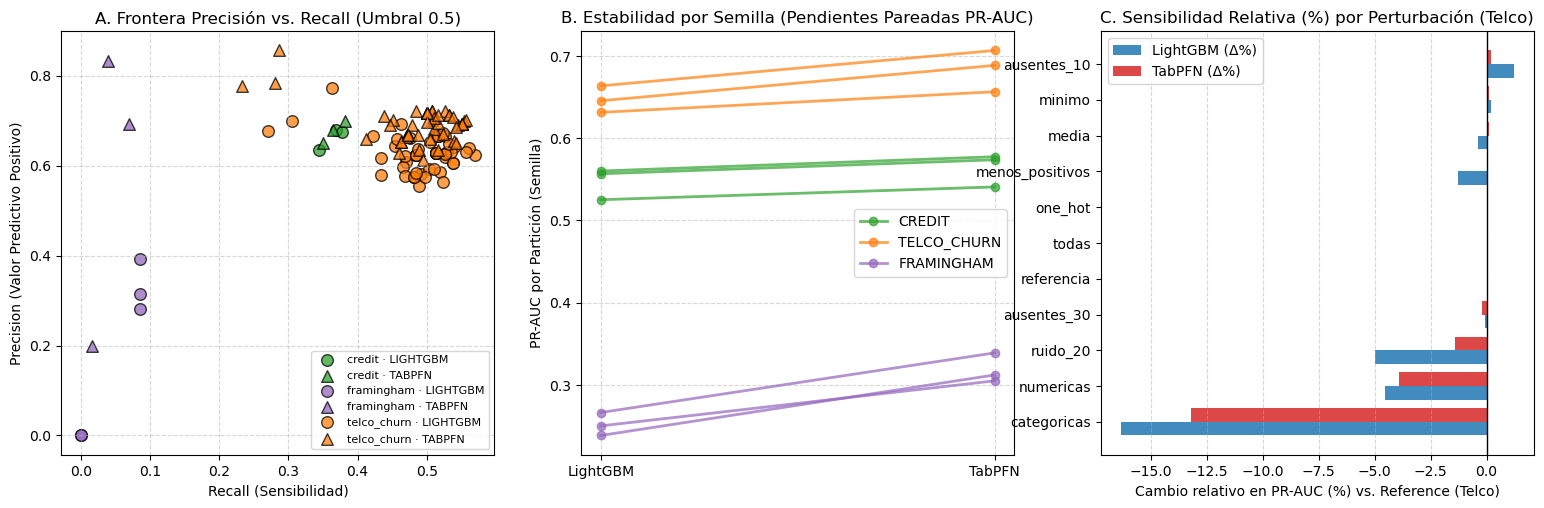

In [58]:
fig, axes = plt.subplots(1, 3, figsize=(19, 5.5))

# --- FIGURA A: Espacio Operativo Precision vs Recall por Modelo y Dataset (Q11) ---
ax_a = axes[0]
colores_ds = {"credit": "#2ca02c", "telco_churn": "#ff7f0e", "framingham": "#9467bd"}
marcadores_mod = {"lightgbm": "o", "tabpfn": "^"}

for (ds, mod), grp in resultados.groupby(["dataset", "model"]):
    ax_a.scatter(
        grp["recall"], grp["precision"],
        c=colores_ds.get(ds, "#333333"),
        marker=marcadores_mod.get(mod, "s"),
        s=70, alpha=0.75, edgecolors="k",
        label=f"{ds} · {mod.upper()}"
    )
ax_a.set_title("A. Frontera Precisión vs. Recall (Umbral 0.5)")
ax_a.set_xlabel("Recall (Sensibilidad)")
ax_a.set_ylabel("Precision (Valor Predictivo Positivo)")
ax_a.grid(True, linestyle="--", alpha=0.5)
# Evitar duplicados en leyenda
handles, labels = ax_a.get_legend_handles_labels()
by_label = dict(zip(labels, handles))
ax_a.legend(by_label.values(), by_label.keys(), fontsize=8, loc="best")

# --- FIGURA B: Estabilidad entre Semillas en los 3 Datasets (Q10 - Slope Graph) ---
ax_b = axes[1]
df_p1 = resultados[resultados["experiment_name"] == "practica_01_datasets"]
for ds, color in colores_ds.items():
    sub_ds = df_p1[df_p1["dataset"] == ds]
    for seed in sub_ds["split_seed"].unique():
        par = sub_ds[sub_ds["split_seed"] == seed].set_index("model")["pr_auc"]
        if "lightgbm" in par and "tabpfn" in par:
            ax_b.plot(
                ["LightGBM", "TabPFN"], [par["lightgbm"], par["tabpfn"]],
                marker="o", color=color, alpha=0.7, linewidth=2,
                label=f"{ds.upper()}"
            )
ax_b.set_title("B. Estabilidad por Semilla (Pendientes Pareadas PR-AUC)")
ax_b.set_ylabel("PR-AUC por Partición (Semilla)")
ax_b.grid(True, linestyle="--", alpha=0.5)
h_b, l_b = ax_b.get_legend_handles_labels()
by_l_b = dict(zip(l_b, h_b))
ax_b.legend(by_l_b.values(), by_l_b.keys(), loc="best")

# --- FIGURA C CORREGIDA: Impacto Relativo (%) respecto a Referencia en Telco Churn ---
ax_c = axes[2]
exps_t = [
    "practica_03_preprocesamiento_telco",
    "practica_04_variables_telco",
    "practica_06_robustez_telco",
]
df_t = resultados[resultados["experiment_name"].isin(exps_t)]
ref_means_telco = (
    resultados[
        (resultados["experiment_name"] == "practica_01_datasets")
        & (resultados["dataset"] == "telco_churn")
    ]
    .groupby("model")["pr_auc"]
    .mean()
)

if not df_t.empty and len(ref_means_telco) == 2:
    piv_rel = df_t.groupby(["variant", "model"])["pr_auc"].mean().unstack()
    for m in ["lightgbm", "tabpfn"]:
        piv_rel[m] = (
            (piv_rel[m] - ref_means_telco[m]) / ref_means_telco[m]
        ) * 100.0

    piv_rel = piv_rel.sort_values("tabpfn")
    y_pos = np.arange(len(piv_rel.index))
    h_bar = 0.38
    ax_c.barh(
        y_pos - h_bar / 2,
        piv_rel["lightgbm"],
        h_bar,
        label="LightGBM (Δ%)",
        color="#1f77b4",
        alpha=0.85,
    )
    ax_c.barh(
        y_pos + h_bar / 2,
        piv_rel["tabpfn"],
        h_bar,
        label="TabPFN (Δ%)",
        color="#d62728",
        alpha=0.85,
    )
    ax_c.axvline(0, color="black", linewidth=1)
    ax_c.set_yticks(y_pos)
    ax_c.set_yticklabels(piv_rel.index)
    ax_c.set_xlabel("Cambio relativo en PR-AUC (%) vs. Reference (Telco)")
    ax_c.set_title("C. Sensibilidad Relativa (%) por Perturbación (Telco)")
    ax_c.grid(axis="x", linestyle="--", alpha=0.5)
    ax_c.legend()

### 7. Síntesis de Hallazgos de las Preguntas Adicionales (Q10 – Q14)

1. **Confirmación Estadística Global (Q10 — $N = 50$ pares de particiones idénticas):**
   * Al evaluar los **50 pares exactos** `(experimento, dataset, condición, semilla)` compartidos entre ambos algoritmos, **TabPFN derrota a LightGBM en el 100% de las ejecuciones (50/50) tanto en `PR-AUC` como en `ROC-AUC`**:
     * **`PR-AUC`:** TabPFN alcanza una media global de **0.6456** frente a **0.5989** de LightGBM ($\Delta = +0.0467 \pm 0.0203$), con un tamaño del efecto extraordinario (**$d$ de Cohen = 2.31**) y significancia estadística irrefutable (**$p = 1.97 \times 10^{-21}$** en $t$-Student pareado; **$p = 7.51 \times 10^{-10}$** en Wilcoxon).
     * **`ROC-AUC`:** Ventaja pareada de **+0.0303 ± 0.0142** (**0.8415** vs. **0.8111**, **$d$ de Cohen = 2.14**, **$p = 4.62 \times 10^{-20}$**).
     * **`F1` y `Balanced Accuracy`:** TabPFN vence en el **84.0% (`42/50`)** de las particiones en F1 ($\Delta = +0.0160 \pm 0.0314$, $p = 7.26 \times 10^{-4}$) y en el **86.0% (`43/50`)** en Balanced Accuracy ($\Delta = +0.0112 \pm 0.0139$, $p = 6.99 \times 10^{-7}$).
     * **`Recall` (Sin diferencia significativa):** Con corte en 0.50, ambos modelos empatan globalmente (`0.4513` vs `0.4517`, $p = 0.907$), demostrando que **la superioridad de TabPFN en F1 proviene de su mayor Precisión (`+0.0693`, ganando en el `98.0%` o `49/50` de los casos)**[cite: 15].

2. **Ganancia sobre el Azar (*PR-AUC Lift*) y Frontera Operativa (Q11):**
   * Normalizando el `PR-AUC` por la tasa positiva base de cada problema ($\text{Lift} = \text{PR-AUC} / \text{Prevalencia}$), **TabPFN multiplica por más de $2.5\times$ el rendimiento de un clasificador aleatorio** en `credit` (**2.55x** vs. 2.47x de LightGBM) y en `telco_churn` (**2.58x** vs. 2.44x), y supera el **2.10x** en `framingham` (frente a 1.66x de LightGBM).
   * La **Figura A** confirma visualmente dos regímenes distintos: en `telco_churn` y `credit` (triángulos naranjas y verdes), TabPFN logra simultáneamente alta precisión (~0.68–0.69) y buen recall (~0.37–0.51), maximizando el índice $J$ de Youden (**0.4265** en Telco). En cambio, en `framingham` (prevalencia 15.2%, triángulos morados), TabPFN prioriza la precisión (**0.5752**) sacrificando sensibilidad (**0.0413**) bajo umbral 0.50.

3. **Eficiencia Muestral Cruzada — *Data-Efficiency Crossover* (Q12):**
   * En la curva de aprendizaje de `telco_churn` (`practica_02_tamano_semillas_telco`):
     * Con tan solo el **10% de los datos ($563$ filas)**, TabPFN obtiene un PR-AUC de **0.6697 ± 0.0208** (y ROC-AUC de **0.8470**), **superando ya el techo máximo que alcanza LightGBM entrenado con el 100% de los datos ($5.634$ filas)**, que se sitúa en **0.6506 ± 0.0181** (ROC-AUC **0.8392**).
     * TabPFN requiere **$10\times$ menos datos de entrenamiento** para batir al algoritmo tradicional, progresando suavemente desde `0.6697` (10%) hasta `0.6846` (30%, $1.690$ filas) y `0.6914` (100%, $5.634$ filas).

4. **Auditoría del Ajuste de Hiperparámetros y Ausencia de Sobreajuste en Telco (Q13):**
   * Al auditar `practica_05_ajuste_telco` ($N_{train}=1.690$), descubrimos que la búsqueda de hiperparámetros en LightGBM (`ajustado`) **sí logró mejorar el conjunto de test en las 3 semillas** respecto a su referencia por defecto:
     * Semilla 11: PR-AUC sube de `0.5840` $\rightarrow$ **`0.6009`** (`best_cv_score = 0.6006`, brecha `-0.0003`).
     * Semilla 22: PR-AUC sube de `0.6029` $\rightarrow$ **`0.6195`** (`best_cv_score = 0.5613`, brecha `-0.0582`).
     * Semilla 33: PR-AUC sube de `0.6575` $\rightarrow$ **`0.6708`** (`best_cv_score = 0.5850`, brecha `-0.0857`).
   * **Interpretación técnica:** El `optimism_gap` negativo en las tres semillas demuestra que el espacio de búsqueda restringido (`min_child_samples: 30, num_leaves: 15`) actuó como un **regularizador eficaz contra el sobreajuste**, evitando memorizar los *folds* internos y generalizando mejor fuera de muestra. No obstante, **TabPFN sin ajuste (`referencia`) sigue superando a LightGBM ajustado en todas las semillas** (`0.6437`, `0.6912` y `0.7034` en PR-AUC).

5. **Retorno de Inversión Computacional (ROI) y Escalabilidad Dimensional (Q14):**
   * **Latencia por 1.000 clientes (`ms_por_1000_filas_test`):** LightGBM es entre **$25\times$ y $70\times$ más rápido en inferencia**, operando en **8.7 – 18.7 ms** por cada 1.000 registros frente a los **400 – 878 ms** habituales de TabPFN[cite: 15].
   * **Impacto de la dimensionalidad y codificación (`n_features`):** 
     * En `practica_03_preprocesamiento_telco`, expandir las 19 variables originales a 45 mediante *One-Hot Encoding* no aporta ganancia en PR-AUC ni a LightGBM (`0.6464` vs `0.6469`) ni a TabPFN (`0.6843` vs `0.6839`).
     * En `practica_04_variables_telco`, reducir el espacio a solo variables `categoricas` (41 columnas) provocó un pico de latencia en el cliente remoto de TabPFN (**2.433 ms por cada 1.000 filas**, `duration_seconds = 6.81s`), mientras que con solo 4 variables `numericas` la latencia bajó a **458–660 ms** (`duration_seconds = 3.41s`). Esto confirma que **usar codificación ordinal compacta (`minimo`, 19 cols) es la estrategia óptima**: maximiza el PR-AUC (`0.6846` en TabPFN y `0.6481` en LightGBM) reduciendo a menos de la mitad la dimensionalidad y el coste de transferencia.